# Lab 18: How to choose an agent design

## Goal

Decide when a second agent pays for itself, by running the support desk's own requests through five designs and
measuring each one: model requests, tokens, seconds, cost, and whether the answer holds every fact. The moment comes
when the table is filled in. On Puja's two-part question, specialists used as tools are right in every run at
8 model requests against 3 for one agent, and a handoff loses the second half in
every run (3 of 3). On the request that names five customers, parallel sub-agents cost more in total
(3,364 input tokens against 2,383 to 2,918), but the agent that writes the answer reads
125 tokens instead of 760 to 791. A second agent is worth its cost only for a job like that one.

## What you will learn

- how to run one request through one agent, specialists as tools, a handoff, parallel sub-agents and a hybrid of code
  and agent, and read requests, tokens, seconds and cost for each from the SDK's usage;
- how to measure the **final context**, what the agent that writes the answer has to read, and why parallel
  sub-agents keep it small;
- why the tool descriptions are the router, by printing what the manager agent reads and measuring vague ones;
- how a hybrid lets our code answer labelled requests with no model call, and what it cannot do;
- how to decide with four reasons to split: different permissions, a smaller context, parallel work, another team or
  model;
- what A2A describes, from an agent card printed beside an MCP `tools/list` entry, and how CrewAI's roles, tasks and
  process map onto the same pieces.

## Where this lab starts

Lab 03 wrote the agent loop by hand, and lab 07 rebuilt it in the OpenAI Agents SDK: an `Agent` holds the
instructions, the model and the tools; `Runner.run` runs the loop (send the messages and tools, run the tool calls the
model asks for, send the results back, stop on an answer); every SDK call is a coroutine, so we `await` it. Lab 07
also wired two specialists four ways on Puja's two-part question and measured one agent at 3 requests and 858 input
tokens, the specialists as tools at 8 requests and about 1,800, and a handoff that lost the rep in every run.

This lab asks the question those numbers raise: **when is a second agent worth it?** We measure again, in this
notebook's own run, and add the designs lab 07 did not have: parallel sub-agents on a request about five customers,
and a hybrid in which our code answers what it can and the agent gets the rest. The lab restates the lookups and the
SDK pieces it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it (lab 00 explains it line by line). This lab adds
`asyncio`, `json`, `re`, `sqlite3` and `time`, all from Python's standard library.

In [1]:
from pathlib import Path
import asyncio
import json
import os
import re
import sqlite3
import time
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Write the desk's requests and their right answers

A design is judged on what it does with real requests, so we fix the requests and their right answers before any
model runs. The answers come from the database, through three plain lookup functions.

### The three lookups, called by hand

The shop's data is `data/chinook.db`, a SQLite file, opened read-only (`mode=ro`) so no tool can change it, and with
`check_same_thread=False` because the SDK may run a tool on another thread than the one that opened the connection.
Each function has **type hints** and a **docstring**: the SDK reads both to describe the function to the model, as
lab 07 showed.

In [2]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}


for name in ["Helena Holý", "Puja Srivastava"]:
    customer = find_customer(name)[0]
    print(customer, get_invoices(customer["customer_id"]), get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'} {'customer_id': 6, 'invoice_count': 7, 'total': 49.62} {'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'} {'customer_id': 59, 'invoice_count': 6, 'total': 36.64} {'customer_id': 59, 'support_rep': 'Jane Peacock'}


Each line is one customer: what `find_customer` returned (a list, here with one match), then the invoice count and
total, then the rep. **Helena Holý** is customer 6 with 7 invoices adding up to $49.62, rep Steve Johnson;
**Puja Srivastava** is customer 59 with 6 invoices adding up to $36.64, rep Jane Peacock.

One request the desk gets names five customers at once. Their totals, by hand:

In [3]:
FIVE = ["Helena Holý", "Puja Srivastava", "Richard Cunningham", "Luis Rojas", "Manoj Pareek"]

for name in FIVE:
    customer_id = find_customer(name)[0]["customer_id"]
    print(f"{name:20} customer {customer_id:2}   total {get_invoices(customer_id)['total']}")

Helena Holý          customer  6   total 49.62
Puja Srivastava      customer 59   total 36.64
Richard Cunningham   customer 26   total 47.62
Luis Rojas           customer 57   total 46.62
Manoj Pareek         customer 58   total 38.62


Five different totals, so a reply that mixes two customers up cannot pass by luck. Helena spent the most.

### Four requests, and what a right answer must contain

The desk's requests differ in shape, and the shape is what decides which design fits:

1. **R1, one destination:** *Who is Helena Holý's support rep?* One fact, owned by one specialist.
2. **R2, two parts:** Puja's invoices and her rep. Two facts owned by two different specialists.
3. **R3, five independent parts:** five customers' totals and who spent the most. The five lookups do not depend on
   each other.
4. **OPEN, a question no form covers:** *Has Helena Holý spent more than Puja Srivastava? By how much?* We use it in
   Part F.

`ANSWERS` holds the facts a right reply must contain. Only the question is ever sent to an agent; the answers stay in
this notebook for the checks.

In [4]:
REQUESTS = {
    "R1": "Who is Helena Holý's support rep?",
    "R2": "How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?",
    "R3": ("What has each of these five customers spent in total: Helena Holý, Puja Srivastava, "
           "Richard Cunningham, Luis Rojas and Manoj Pareek? Who spent the most?"),
    "OPEN": "Has Helena Holý spent more than Puja Srivastava? By how much?",
}

# The facts a right reply must contain, from the lookups above
ANSWERS = {
    "R1": ["Steve Johnson"],
    "R2": ["6", "36.64", "Jane Peacock"],
    "R3": ["49.62", "36.64", "47.62", "46.62", "38.62"],
    "OPEN": ["12.98"],
}
print("Helena minus Puja:", round(49.62 - 36.64, 2))

Helena minus Puja: 12.98


The difference for OPEN is $12.98, worked out here so the check has a number to look for.

`facts_found` checks a reply for each fact and returns one `True` or `False` per fact. `\b` in the pattern is a word
boundary, so `6` must stand alone and is not found inside `36.64`; `re.escape` makes the `.` in `36.64` a plain dot.
We try it on two replies we wrote, one complete and one without the rep:

In [5]:
def facts_found(text, facts):
    return [bool(re.search(rf"\b{re.escape(fact)}\b", text or "")) for fact in facts]


print(facts_found("Puja Srivastava has 6 invoices totaling $36.64; her rep is Jane Peacock.", ANSWERS["R2"]))
print(facts_found("Puja Srivastava has 6 invoices totaling $36.64.", ANSWERS["R2"]))

[True, True, True]
[True, True, False]


`[True, True, True]` for the complete reply and `[True, True, False]` for the one without the rep. A pass means each
number or name appears in the reply; it does not check that the sentence around it is right (that R3 names the
right top spender, for example), so we also read the replies.

### The five designs we will measure

In the picture, ink marks where a model decides what happens next, and lime where our code does:

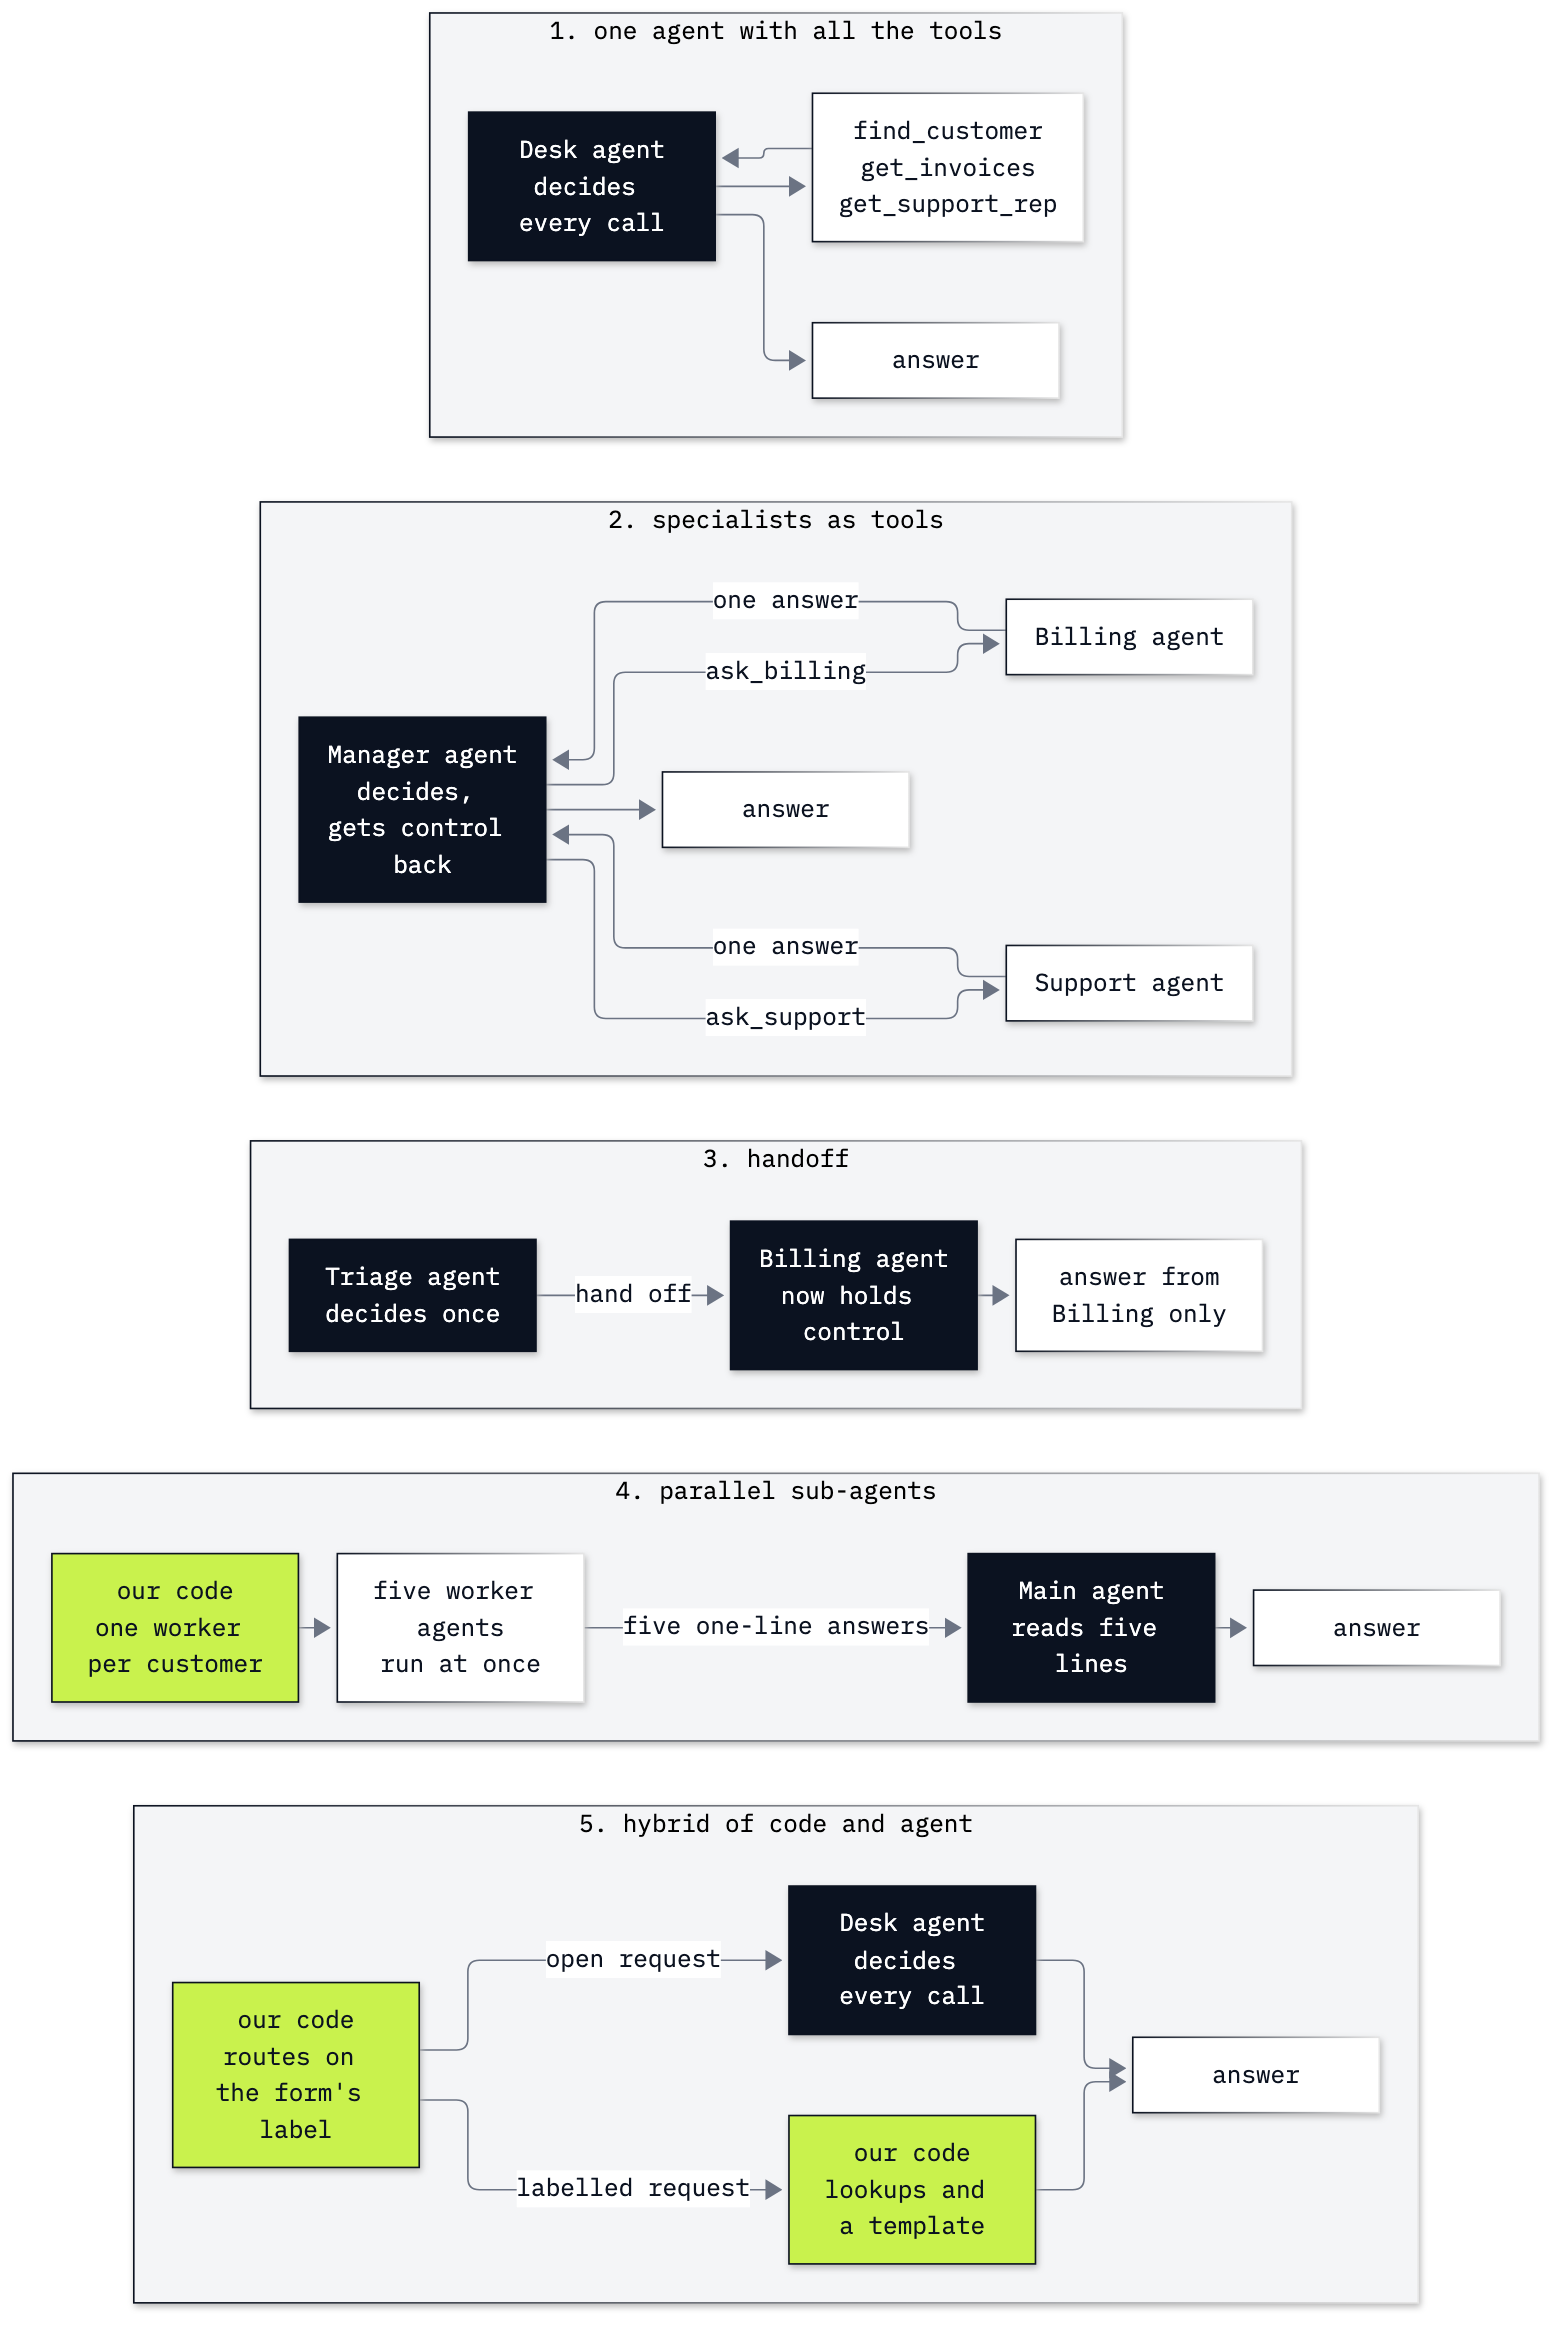

In [6]:
from IPython.display import Image

Image(filename="resources/lab18_designs.png", width=760)

1. **One agent with all the tools:** the baseline. One model decides every lookup.
2. **Specialists as tools:** a manager agent asks a Billing agent and a Support agent, each with its own tools, and
   gets control back after each.
3. **A handoff:** a triage agent passes the whole conversation to one specialist, which takes over.
4. **Parallel sub-agents:** our code starts one small worker agent per customer, all at once; each returns one line,
   and a main agent writes the answer from those lines.
5. **A hybrid of code and agent:** our code answers the requests whose type it knows, with no model, and sends the
   rest to the agent.

**Checkpoint A.** Helena 6, 7 invoices, $49.62, Steve Johnson; Puja 59, 6, $36.64, Jane Peacock; five different
totals, Helena's the largest; `facts_found` gives `[True, True, True]` and `[True, True, False]` on the two test
replies.

---

## Part B: Measure one agent with all the tools

Every other design adds agents, calls or code to this one, so it is the row the others must beat. This part builds
the agent, runs it once and reads the numbers by hand, then packages that reading so every later run is measured the
same way.

### The desk agent

`function_tool` turns each lookup into a tool the model can ask for (its name, its docstring as the description, its
type hints as the argument schema). The `Agent` gets the instructions, the model and the tools, and
`model_settings` with the reasoning effort from `models.env` (the SDK does not set it for our model by itself; lab 07
shows why). This lab reads usage, not traces, so `set_tracing_disabled(True)` turns the SDK's trace upload off.

In [7]:
from agents import Agent, ModelSettings, Runner, function_tool, set_tracing_disabled
from openai.types.shared import Reasoning

# This lab reads usage, not traces: tracing off, so nothing is uploaded
set_tracing_disabled(True)

SETTINGS = ModelSettings(reasoning=Reasoning(effort=EFFORT))
FIND, INVOICES, REP = function_tool(find_customer), function_tool(get_invoices), function_tool(get_support_rep)
RULE = "Look up every fact with your tools; never answer from memory. Answer briefly."

desk = Agent(name="Desk", instructions="You help the support reps of a music shop. " + RULE,
             model=MODEL, tools=[FIND, INVOICES, REP], model_settings=SETTINGS)

print("name: ", desk.name)
print("tools:", [tool.name for tool in desk.tools])
print("effort:", desk.model_settings.reasoning.effort)

name:  Desk
tools: ['find_customer', 'get_invoices', 'get_support_rep']
effort: none


One agent, three tools, effort from `models.env`. Nothing has been sent to the model yet: an `Agent` is a
description.

### One run, read by hand

We run R1 and time it with `time.perf_counter()`, a clock in seconds. `result.raw_responses` has one entry per model
request, each with the parts of that reply. `getattr(part, "name", part.type)` prints a part's `name` when it has one
(a tool call does) and its `type` otherwise, so the answer shows as `message`.

In [8]:
t0 = time.perf_counter()
result = await Runner.run(desk, REQUESTS["R1"])
seconds = time.perf_counter() - t0

print(result.final_output)
print("seconds:", round(seconds, 1))
for number, response in enumerate(result.raw_responses, start=1):
    print(f"request {number}:", [getattr(part, "name", part.type) for part in response.output])

Helena Holý’s support rep is Steve Johnson.
seconds: 6.6
request 1: ['find_customer']
request 2: ['get_support_rep']
request 3: ['message']


Helena's rep, Steve Johnson, in 6.6 seconds and three model requests: `find_customer` first, then `get_support_rep` with the id it returned, then the answer (`message`). The second lookup needs the first one's `customer_id`, so the two could not go in one reply.

### What the run cost

`result.context_wrapper.usage` adds up every model request of the run:

- `requests`: how many times the model was called;
- `input_tokens`: the tokens sent, over all requests; `request_usage_entries` keeps each request's own count;
- `output_tokens`: the tokens the model wrote.

One more number matters for this lab: the input tokens of the **last** request,
`result.raw_responses[-1].usage.input_tokens`. Each request re-sends the whole conversation so far, so the last one is
everything the agent had to read to write its answer. We call it the **final context**. The cost uses the list
prices in `models.env`.

In [9]:
usage = result.context_wrapper.usage
price_in = float(settings["PRICE_INPUT_PER_MILLION"]) / 1_000_000
price_out = float(settings["PRICE_OUTPUT_PER_MILLION"]) / 1_000_000

print("requests:     ", usage.requests)
print("input tokens: ", usage.input_tokens, "=", " + ".join(str(e.input_tokens) for e in usage.request_usage_entries))
print("output tokens:", usage.output_tokens)
print("final context:", result.raw_responses[-1].usage.input_tokens)
print(f"cost:          ${usage.input_tokens * price_in + usage.output_tokens * price_out:.6f}")

requests:      3
input tokens:  727 = 188 + 246 + 293
output tokens: 56
final context: 293
cost:          $0.000101


Three requests, 727 input tokens (188 + 246 + 293), 56 output tokens, and a final context of 293 tokens: the last request carried the question, both lookups and their results. At the list prices the run cost $0.000101, about a hundredth of a US cent.

The input grows request by request because each request carries the earlier ones: the question, then the
`find_customer` call and its result, then the `get_support_rep` call and its result. Every prompt here stays under
1,024 tokens, the size at which prompt caching starts, so all input is billed at the full input price.

### Measure every run the same way

We will make about fifty runs. Reading each by hand would repeat the last two cells, so we package them. First, the
numbers we just read, taken from any `RunResult`; `turns` keeps the tool names of each request, so we can see later
what the model did:

In [10]:
ROWS = []  # one dict per measured run; Part G turns them into a table


def numbers_from(result):
    """The numbers read by hand above, from one RunResult."""
    usage = result.context_wrapper.usage
    return {"requests": usage.requests, "input": usage.input_tokens, "output": usage.output_tokens,
            "final_context": result.raw_responses[-1].usage.input_tokens,
            "turns": [[getattr(part, "name", part.type) for part in r.output] for r in result.raw_responses]}


async def run_agent(agent, question):
    result = await Runner.run(agent, question)
    return result.final_output, numbers_from(result)

Then `measure`, which runs one design on one request three times. For each run, step by step:

1. it calls `run_once()`, which makes and runs a new coroutine and gives back the reply and its numbers;
2. it times the call, checks the reply with `facts_found` and prices the tokens;
3. it appends one dict to `ROWS` (`**numbers` copies the numbers' keys into it) and prints one line.

We pass `run_once` as `lambda: run_agent(desk, ...)`: a function with no arguments that makes a **new** coroutine
each time it is called. A coroutine runs only once, so three runs need three of them.

In [11]:
async def measure(design, key, run_once, runs=3):
    for n in range(1, runs + 1):
        t0 = time.perf_counter()
        text, numbers = await run_once()
        seconds = time.perf_counter() - t0
        found = facts_found(text, ANSWERS[key])
        cost = numbers["input"] * price_in + numbers["output"] * price_out
        ROWS.append({"design": design, "request": key, "run": n, "text": text, "seconds": seconds,
                     "right": all(found), "cost": cost, **numbers})
        print(f"{design:19} {key:4} run {n} | facts {sum(found)}/{len(found)} {'✅' if all(found) else '❌'} | "
              f"requests {numbers['requests']:2} | input {numbers['input']:5} | "
              f"final context {numbers['final_context']:4} | {seconds:4.1f} s | ${cost:.6f}")

### One agent on R1, R2 and R3

Before you run it: which request will need the most tokens, and why?

In [12]:
for key in ["R1", "R2", "R3"]:
    await measure("one agent", key, lambda: run_agent(desk, REQUESTS[key]))

one agent           R1   run 1 | facts 1/1 ✅ | requests  3 | input   727 | final context  293 |  5.6 s | $0.000101


one agent           R1   run 2 | facts 1/1 ✅ | requests  3 | input   727 | final context  293 |  7.5 s | $0.000101


one agent           R1   run 3 | facts 1/1 ✅ | requests  3 | input   727 | final context  293 |  6.0 s | $0.000101


one agent           R2   run 1 | facts 3/3 ✅ | requests  3 | input   846 | final context  376 |  7.5 s | $0.000138


one agent           R2   run 2 | facts 3/3 ✅ | requests  3 | input   846 | final context  376 |  8.3 s | $0.000138


one agent           R2   run 3 | facts 3/3 ✅ | requests  3 | input   846 | final context  376 |  8.2 s | $0.000138


one agent           R3   run 1 | facts 5/5 ✅ | requests  5 | input  2383 | final context  791 | 13.1 s | $0.000389


one agent           R3   run 2 | facts 5/5 ✅ | requests  7 | input  2918 | final context  760 | 19.8 s | $0.000434


one agent           R3   run 3 | facts 5/5 ✅ | requests  7 | input  2918 | final context  760 | 19.1 s | $0.000430


Every reply had every fact. R1 and R2 took 3 requests in each run (727 and 846 input tokens; three requests for R2's three lookups means the two after `find_customer` went in one reply). R3 is where the numbers spread: 5 to 7 requests and 2,383 to 2,918 input tokens, with a final context of 760 to 791 tokens, the largest of the three requests by far. Each lookup's result stays in the conversation, and five customers mean ten results.

What did the agent do on R3? `turns` holds the tool names of each request. `Counter` counts how often each name
appears in a list, so `5 x find_customer` means five calls in one reply:

In [13]:
from collections import Counter

for row in ROWS:
    if row["design"] == "one agent" and row["request"] == "R3":
        steps = [", ".join(f"{n} x {name}" for name, n in Counter(calls).items()) for calls in row["turns"]]
        print(f"run {row['run']}:", " | ".join(steps))
print()
print(ROWS[-1]["text"])

run 1: 1 x find_customer | 4 x find_customer, 1 x get_invoices | 1 x find_customer | 4 x get_invoices | 1 x message
run 2: 1 x find_customer | 1 x find_customer | 1 x find_customer | 1 x find_customer | 1 x find_customer | 5 x get_invoices | 1 x message
run 3: 1 x find_customer | 1 x find_customer | 1 x find_customer | 1 x find_customer | 1 x find_customer | 5 x get_invoices | 1 x message

- Helena Holý: **$49.62**
- Puja Srivastava: **$36.64**
- Richard Cunningham: **$47.62**
- Luis Rojas: **$46.62**
- Manoj Pareek: **$38.62**

**Helena Holý spent the most.**


The three runs took different paths to the same answer. In run 1 the model looked up one customer, then four customers and one total in one reply, then one more customer, then four totals. Runs 2 and 3 looked the five customers up one per request, then asked for all five totals in one reply. Nothing tells the model to batch its calls, so it chooses the shape on every run: over 19 runs of R3 on the same model, it took 3 requests (all five customers in one reply, then all five totals) in 8, and up to 8 requests in the others. The reply printed last (run 3) is right, with Helena on top.

**Checkpoint B.** One agent right on R1, R2 and R3 in every run; R1 3 requests and 727 input tokens, R2 3 and 846; R3 more requests and tokens that change from run to run (ours: 5 to 7 requests, 2,383 to 2,918 tokens), with the largest final context (ours: 760 to 791).

---

## Part C: Measure specialists as tools

A common reason to add agents is that parts of the work belong to different specialists, each with its own tools
(and, in a real shop, its own permissions). This part gives billing and support their own agents, puts a manager
over them, and measures what it costs when control comes back to the manager after each specialist.

### Two specialists, each with only its own tools

**Billing** can find a customer and read their invoices; **Support** can find a customer and name their rep. Neither
can do the other's job. `handoff_description` is a sentence another agent reads about this one; Part D uses it.

In [14]:
billing = Agent(name="Billing",
                handoff_description="Answers questions about a customer's invoices: how many, and their total.",
                instructions="You answer questions about a customer's invoices. " + RULE,
                model=MODEL, tools=[FIND, INVOICES], model_settings=SETTINGS)
support = Agent(name="Support",
                handoff_description="Answers who a customer's support rep is.",
                instructions="You answer who looks after a customer. " + RULE,
                model=MODEL, tools=[FIND, REP], model_settings=SETTINGS)

for agent in [billing, support]:
    print(f"{agent.name:8}", [tool.name for tool in agent.tools])

Billing  ['find_customer', 'get_invoices']
Support  ['find_customer', 'get_support_rep']


### The manager, and what its model reads

`agent.as_tool(tool_name, tool_description)` wraps a whole agent as one tool. When the manager calls it, the SDK runs
that agent (a full run with its own turns and its own lookups) on an `input` string the manager writes, and returns
the agent's final answer as the tool's result. The manager then carries on.

The manager's model never sees the specialists' lookups. It sees a name, a description and one string argument per
specialist, and chooses from those words alone. That is why **the tool descriptions are the router**: we print
exactly what the model reads.

In [15]:
manager = Agent(
    name="Manager",
    instructions=("You help the support reps of a music shop. Ask the specialists for every fact; "
                  "never answer from memory. Answer briefly."),
    model=MODEL, model_settings=SETTINGS,
    tools=[
        billing.as_tool(tool_name="ask_billing",
                        tool_description=("Ask the billing specialist about a customer's invoices: how many, and "
                                          "their total. It cannot name a support rep.")),
        support.as_tool(tool_name="ask_support",
                        tool_description=("Ask the support specialist who a customer's support rep is. "
                                          "It cannot count invoices.")),
    ],
)

# What the manager's model reads about each specialist
for tool in manager.tools:
    print(tool.name, "|", tool.description, "| arguments:", list(tool.params_json_schema["properties"]))

ask_billing | Ask the billing specialist about a customer's invoices: how many, and their total. It cannot name a support rep. | arguments: ['input']
ask_support | Ask the support specialist who a customer's support rep is. It cannot count invoices. | arguments: ['input']


Two tools, each described by what it does and what it cannot do, each with one argument, `input`. The descriptions
are sharp on purpose: each names the specialist's facts and the facts it does not have.

### The manager on R1 and R2

In [16]:
for key in ["R1", "R2"]:
    await measure("as tools", key, lambda: run_agent(manager, REQUESTS[key]))

print()
print("manager's own requests on the last R2 run:", ROWS[-1]["turns"])

as tools            R1   run 1 | facts 1/1 ✅ | requests  5 | input   984 | final context  214 | 13.4 s | $0.000147


as tools            R1   run 2 | facts 1/1 ✅ | requests  5 | input   984 | final context  214 | 17.3 s | $0.000147


as tools            R1   run 3 | facts 1/1 ✅ | requests  5 | input   984 | final context  214 | 11.0 s | $0.000147


as tools            R2   run 1 | facts 3/3 ✅ | requests  8 | input  1792 | final context  320 | 16.9 s | $0.000300


as tools            R2   run 2 | facts 3/3 ✅ | requests  8 | input  1790 | final context  318 | 15.3 s | $0.000296


as tools            R2   run 3 | facts 3/3 ✅ | requests  8 | input  1787 | final context  315 | 13.5 s | $0.000295

manager's own requests on the last R2 run: [['ask_billing', 'ask_support'], ['message']]


Right in every run, at a price: 5 requests on R1 against the one agent's 3, and 8 on R2 against 3 (1,787 to 1,792 input tokens against 846, about twice). The manager's own requests explain the count: it asked both specialists in one reply, then wrote the answer, so 2 requests are the manager's, and each specialist ran its own 3 (find the customer, look up, answer): 2 + 3 + 3 = 8. On R1 the manager asked only Support: 2 + 3 = 5. The manager's final context is smaller than one agent's (315 to 320 tokens against 376) because it reads two short answers instead of the lookups: the effect Part E measures on a larger request.

### What the router does with vague descriptions

What if both specialists were described the same way and their names said nothing? A manager can then only guess.
We make a copy of the manager (`clone` copies an agent and replaces the fields we pass) with neutral names and one
vague description for both, and run R1, which needs only Support.

In [17]:
VAGUE = "Looks up a customer."
vague_manager = manager.clone(tools=[
    billing.as_tool(tool_name="ask_specialist_1", tool_description=VAGUE),
    support.as_tool(tool_name="ask_specialist_2", tool_description=VAGUE),
])
for tool in vague_manager.tools:
    print(tool.name, "|", tool.description)
print()

await measure("as tools, vague", "R1", lambda: run_agent(vague_manager, REQUESTS["R1"]))
for row in ROWS:
    if row["design"] == "as tools, vague":
        print(f"run {row['run']}: the manager's requests:", row["turns"])

ask_specialist_1 | Looks up a customer.
ask_specialist_2 | Looks up a customer.



as tools, vague     R1   run 1 | facts 1/1 ✅ | requests  9 | input  1885 | final context  262 | 24.8 s | $0.000287


as tools, vague     R1   run 2 | facts 1/1 ✅ | requests  8 | input  1588 | final context  269 | 24.0 s | $0.000251


as tools, vague     R1   run 3 | facts 1/1 ✅ | requests  8 | input  1577 | final context  263 | 20.8 s | $0.000247
run 1: the manager's requests: [['ask_specialist_1'], ['ask_specialist_2'], ['message']]
run 2: the manager's requests: [['ask_specialist_1'], ['ask_specialist_2'], ['message']]
run 3: the manager's requests: [['ask_specialist_1'], ['ask_specialist_2'], ['message']]


No wrong answer, and no wrong specialist either: with nothing to tell them apart, the manager asked **both**, one after the other, in every run, then answered with Steve Johnson. R1 took 8 or 9 requests and 1,577 to 1,885 input tokens instead of 5 and 984, and 20.8 to 24.8 seconds against 11.0 to 17.3. On this model a vague description did not make the manager pick the wrong specialist; it made it pay for both. The descriptions are all the manager routes on, so sharp ones (what the specialist does and what it cannot do) are the cheapest fix.

**Checkpoint C.** The manager reads two tools, each with a name, a description and an `input` argument; specialists as tools right on R1 and R2 in every run, at 5 and 8 requests (one agent: 3 and 3); with vague descriptions the manager asked both specialists on R1 in every run (ours: 8 or 9 requests).

---

## Part D: Measure a handoff

A front desk often sends each request to the one team that owns it, and that team talks to the customer from then on.
A **handoff** does that: the triage agent passes the whole conversation to a specialist, which takes over; its answer
is the run's answer, and control does not come back.

The triage agent gets `handoffs=[...]` instead of tools. The SDK shows each handoff to the model as a tool named
`transfer_to_...`, described by the target's `handoff_description`. `handoff(agent)` builds that object, so we can
print what the triage model reads:

In [18]:
from agents import handoff

triage = Agent(name="Triage",
               instructions=("You route each request to the right specialist. Hand off to Billing for invoice counts "
                             "and totals, and to Support for who looks after a customer."),
               model=MODEL, handoffs=[billing, support], model_settings=SETTINGS)

for target in triage.handoffs:
    print(handoff(target).tool_name, "|", handoff(target).tool_description)

transfer_to_billing | Handoff to the Billing agent to handle the request. Answers questions about a customer's invoices: how many, and their total.
transfer_to_support | Handoff to the Support agent to handle the request. Answers who a customer's support rep is.


Two transfer tools, each with its target's description. Before you run it: R2 needs both specialists, and a handoff
gives the conversation to one. What will the reply hold?

We run R2 once and print the run's items: `handoff_call_item` is a handoff the model asked for,
`handoff_output_item` the handoff that happened, and the tool items are the specialist's lookups.

In [19]:
handed = await Runner.run(triage, REQUESTS["R2"])
print(handed.final_output)
print("last agent:", handed.last_agent.name)
print()
for item in handed.new_items:
    if item.type == "handoff_call_item":
        print("handoff asked:", item.raw_item.name)
    elif item.type == "handoff_output_item":
        print("handoff:      ", item.source_agent.name, "->", item.target_agent.name)
    elif item.type == "tool_call_item":
        print("tool call:    ", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("result:       ", item.output)

Puja Srivastava has **6 invoices**, totaling **$36.64**. I couldn’t look up her support representative with the available tools.
last agent: Billing

handoff asked: transfer_to_billing
handoff asked: transfer_to_support
result:        Multiple handoffs detected, ignoring this one.
handoff:       Triage -> Billing
tool call:     find_customer {"name":"Puja Srivastava"}
result:        [{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}]
tool call:     get_invoices {"customer_id":59}
result:        {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}


The rep is missing, and nothing failed loudly: `last agent` is `Billing`, which wrote the answer and said it could not look the rep up. The items show why. The triage model saw both halves: its one reply asked for two handoffs, `transfer_to_billing` and `transfer_to_support`. A handoff gives the conversation to one agent, so the SDK took the first and answered the second with *Multiple handoffs detected, ignoring this one.* Billing then found Puja and read her invoices; `get_support_rep` was never called, because no agent that held control had it.

### The handoff on R1 and R2, measured

In [20]:
for key in ["R1", "R2"]:
    await measure("handoff", key, lambda: run_agent(triage, REQUESTS[key]))

handoff             R1   run 1 | facts 1/1 ✅ | requests  4 | input   830 | final context  285 | 12.5 s | $0.000119


handoff             R1   run 2 | facts 1/1 ✅ | requests  4 | input   830 | final context  285 | 10.5 s | $0.000127


handoff             R1   run 3 | facts 1/1 ✅ | requests  4 | input   830 | final context  285 | 11.8 s | $0.000119


handoff             R2   run 1 | facts 2/3 ❌ | requests  4 | input  1071 | final context  365 | 12.2 s | $0.000168


handoff             R2   run 2 | facts 2/3 ❌ | requests  4 | input  1071 | final context  365 | 11.6 s | $0.000167


handoff             R2   run 3 | facts 2/3 ❌ | requests  4 | input  1071 | final context  365 | 11.6 s | $0.000168


Every handoff reply that missed a fact, in full:

In [21]:
for row in ROWS:
    if row["design"] == "handoff" and not row["right"]:
        print(f"{row['request']} run {row['run']}: {row['text']}")

R2 run 1: Puja Srivastava has 6 invoices totaling $36.64. I couldn’t look up her support rep with the available tools.
R2 run 2: Puja Srivastava has 6 invoices totaling $36.64. I couldn’t verify who her support rep is.
R2 run 3: Puja Srivastava has 6 invoices totaling $36.64. I couldn’t look up her support rep with the available tools.


R1 was right in every run at 4 requests (one for the triage, then Support's three): one destination, and the handoff fits it. R2 lost the rep in every run (3 of 3), at 4 requests and 1,071 input tokens, cheaper than the specialists as tools because half the work was never done. The replies admit the gap, but a check that only looked for an answer would pass them.

**Checkpoint D.** Two `transfer_to_` tools; R1 right in every run, `last agent` Support; R2 with the invoices and without the rep in every run, two handoffs asked, and *Multiple handoffs detected, ignoring this one.* for the second.

---

## Part E: Measure parallel sub-agents

R3 is five lookups that do not depend on each other. In Part B one agent did them all, and its final context held
every call and every result. A different design splits the work: one small **worker** agent per customer, all running
at the same time, each returning one line; then a **main** agent writes the answer from five lines. This part
measures what that buys and what it costs.

### Running coroutines at once with `asyncio.gather`

`await` waits for one coroutine. `asyncio.gather(...)` starts several coroutines, waits until the last one is done,
and returns their results in the order of its arguments. Two one-second waits, gathered:

In [22]:
async def pause(name, seconds):
    await asyncio.sleep(seconds)
    return name


t0 = time.perf_counter()
print(await asyncio.gather(pause("a", 1), pause("b", 1)), round(time.perf_counter() - t0, 1), "seconds")

['a', 'b'] 1.0 seconds


Both results, in argument order, in 1.0 seconds rather than 2: the two waits overlapped. A model call is mostly waiting for the reply, so model calls overlap the same way.

### One worker, on one customer

The worker has only the two tools it needs and is told to reply with one line:

In [23]:
worker = Agent(name="Customer worker",
               instructions=("You look up one customer's total spend. Look up every fact with your tools; never "
                             "answer from memory. Reply with one line: the name and the total in dollars."),
               model=MODEL, tools=[FIND, INVOICES], model_settings=SETTINGS)

one_worker = await Runner.run(worker, "What has Helena Holý spent in total?")
print(one_worker.final_output)
print({name: value for name, value in numbers_from(one_worker).items() if name != "turns"})

Helena Holý — $49.62
{'requests': 3, 'input': 650, 'output': 54, 'final_context': 272}


One line, *Helena Holý — $49.62*, from 3 requests (find, look up, answer) and 650 input tokens; the worker's final context was 272 tokens. Its lookups stay inside its own run: whoever reads its answer reads one line.

### Five workers at once

`[Runner.run(worker, ...) for name in FIVE]` builds five coroutines without running them; the `*` passes them to
`gather` as five arguments. `zip(FIVE, worker_runs)` pairs each name with its result, which is right because `gather`
keeps the order of its arguments.

In [24]:
t0 = time.perf_counter()
worker_runs = await asyncio.gather(*[Runner.run(worker, f"What has {name} spent in total?") for name in FIVE])
print("seconds:", round(time.perf_counter() - t0, 1))
for name, run in zip(FIVE, worker_runs):
    print(f"{name:20} -> {run.final_output}   ({run.context_wrapper.usage.requests} requests)")

seconds: 9.8
Helena Holý          -> Helena Holý — $49.62   (3 requests)
Puja Srivastava      -> Puja Srivastava — $36.64   (3 requests)
Richard Cunningham   -> Richard Cunningham — $47.62   (3 requests)
Luis Rojas           -> Luis Rojas — $46.62   (3 requests)
Manoj Pareek         -> Manoj Pareek — $38.62   (3 requests)


Five lines, in the order of `FIVE`, each from 3 requests, in 9.8 seconds for all five: about the time of one worker's run, not five.

### The main agent reads five lines

The main agent has no tools. Its input is the request and the five lines, which we print in full: this is the whole
of what it reads.

In [25]:
main = Agent(name="Main",
             instructions="You help the support reps of a music shop. Answer from the lines you are given; do not add facts.",
             model=MODEL, model_settings=SETTINGS)

main_input = REQUESTS["R3"] + "\n\nWhat the workers found:\n" + "\n".join(run.final_output for run in worker_runs)
print(main_input)
print("---")
joined = await Runner.run(main, main_input)
print(joined.final_output)
print()
print("main agent's context:", joined.raw_responses[-1].usage.input_tokens, "tokens")
print("one agent's final context on R3 (Part B):",
      [row["final_context"] for row in ROWS if row["design"] == "one agent" and row["request"] == "R3"])

What has each of these five customers spent in total: Helena Holý, Puja Srivastava, Richard Cunningham, Luis Rojas and Manoj Pareek? Who spent the most?

What the workers found:
Helena Holý — $49.62
Puja Srivastava — $36.64
Richard Cunningham — $47.62
Luis Rojas — $46.62
Manoj Pareek — $38.62
---


- Helena Holý: $49.62
- Puja Srivastava: $36.64
- Richard Cunningham: $47.62
- Luis Rojas: $46.62
- Manoj Pareek: $38.62

Helena Holý spent the most, at $49.62.

main agent's context: 125 tokens
one agent's final context on R3 (Part B): [791, 760, 760]


The main agent's whole input is the question and five lines, and its context is 125 tokens. One agent's final context on the same request was 760 to 791 tokens in Part B, about six times as much, because it carried every call and every result. The answer is the same: five totals, Helena on top.

### The whole design, measured

`run_parallel` packages the last three cells: gather the workers, join their lines, run the main agent, and add up
the numbers of all six runs. The final context is the main agent's, since it writes the answer.

In [26]:
async def run_parallel(names, question):
    worker_runs = await asyncio.gather(*[Runner.run(worker, f"What has {name} spent in total?") for name in names])
    lines = "\n".join(run.final_output for run in worker_runs)
    joined = await Runner.run(main, question + "\n\nWhat the workers found:\n" + lines)
    runs = [*worker_runs, joined]
    return joined.final_output, {
        "requests": sum(run.context_wrapper.usage.requests for run in runs),
        "input": sum(run.context_wrapper.usage.input_tokens for run in runs),
        "output": sum(run.context_wrapper.usage.output_tokens for run in runs),
        "final_context": joined.raw_responses[-1].usage.input_tokens,
        "turns": [],
    }


await measure("parallel sub-agents", "R3", lambda: run_parallel(FIVE, REQUESTS["R3"]))

parallel sub-agents R3   run 1 | facts 5/5 ✅ | requests 16 | input  3364 | final context  125 | 15.0 s | $0.000506


parallel sub-agents R3   run 2 | facts 5/5 ✅ | requests 16 | input  3364 | final context  125 | 12.5 s | $0.000506


parallel sub-agents R3   run 3 | facts 5/5 ✅ | requests 16 | input  3364 | final context  125 | 12.8 s | $0.000506


Right in every run, with the same shape every time: 16 requests (five workers of 3, plus the main agent's 1) and 3,364 input tokens, because our code fixed the split. The final context stays at 125. Against one agent on R3 (Part B: 5 to 7 requests, 2,383 to 2,918 input tokens), the split cost more tokens in total (about 15 to 40 percent more here) and did not save time (12.5 to 15.0 seconds against 13.1 to 19.8). What it bought is the small final context: the agent that answers reads lines, not lookups. Each worker here reads little, so that matters little; it matters when each part reads a lot (a long ticket history, twenty policy files) and returns one line.

**Checkpoint E.** Two one-second waits gathered in 1.0 seconds; one worker 3 requests and one line; five workers at once, five lines; the main agent's context 125 tokens against one agent's 760 to 791 on R3; parallel sub-agents right in every run at 16 requests and 3,364 input tokens.

---

## Part F: Measure a hybrid of code and agent

Many requests reach a desk through a form, where the rep picks the request type from a list and types a name. When
the type is known, the steps are known too, and our code can run them without a model: no tokens, no waiting, the
same path every time. The agent is kept for what the form does not cover. This part builds that **hybrid**: our code
routes on the form's label.

### The form's requests

Each request is a dict: `kind` is the label the rep picked; the other fields are what the form asked for. The fourth
request is free text, so its kind is `open`.

In [27]:
FORM = [
    {"kind": "support_rep", "customer": "Helena Holý"},
    {"kind": "invoices_and_rep", "customer": "Puja Srivastava"},
    {"kind": "totals", "customers": FIVE},
    {"kind": "open", "text": REQUESTS["OPEN"]},
]
for request in FORM:
    print(request)

{'kind': 'support_rep', 'customer': 'Helena Holý'}
{'kind': 'invoices_and_rep', 'customer': 'Puja Srivastava'}
{'kind': 'totals', 'customers': ['Helena Holý', 'Puja Srivastava', 'Richard Cunningham', 'Luis Rojas', 'Manoj Pareek']}
{'kind': 'open', 'text': 'Has Helena Holý spent more than Puja Srivastava? By how much?'}


The first three are R1, R2 and R3 as a form would send them; the fourth is OPEN.

### A handler per label

Each handler is the lookups from Part A in a fixed order, and a sentence template. `max(totals, key=totals.get)`
returns the dict key whose value is largest, here the top spender's name.

In [28]:
def customer_id_of(name):
    return find_customer(name)[0]["customer_id"]


def answer_support_rep(request):
    rep = get_support_rep(customer_id_of(request["customer"]))["support_rep"]
    return f"{request['customer']}'s support rep is {rep}."


def answer_invoices_and_rep(request):
    customer_id = customer_id_of(request["customer"])
    invoices = get_invoices(customer_id)
    rep = get_support_rep(customer_id)["support_rep"]
    return (f"{request['customer']} has {invoices['invoice_count']} invoices adding up to "
            f"${invoices['total']:.2f}; their support rep is {rep}.")


def answer_totals(request):
    totals = {name: get_invoices(customer_id_of(name))["total"] for name in request["customers"]}
    lines = [f"{name}: ${total:.2f}" for name, total in totals.items()]
    return "\n".join(lines) + f"\n{max(totals, key=totals.get)} spent the most."


HANDLERS = {"support_rep": answer_support_rep, "invoices_and_rep": answer_invoices_and_rep, "totals": answer_totals}

for request in FORM[:3]:
    print(HANDLERS[request["kind"]](request))
    print()

Helena Holý's support rep is Steve Johnson.

Puja Srivastava has 6 invoices adding up to $36.64; their support rep is Jane Peacock.

Helena Holý: $49.62
Puja Srivastava: $36.64
Richard Cunningham: $47.62
Luis Rojas: $46.62
Manoj Pareek: $38.62
Helena Holý spent the most.



Three answers with every fact, and no model in sight: the code knew the steps because the label told it.

### The router

`route` looks the label up in `HANDLERS`. A known label runs its handler and reports zero model requests; anything
else goes to the desk agent from Part B. `HANDLERS.get(kind)` returns `None` for an unknown label instead of raising
an error, which is what sends `open` to the agent.

In [29]:
NO_MODEL = {"requests": 0, "input": 0, "output": 0, "final_context": 0, "turns": []}


async def route(request):
    handler = HANDLERS.get(request["kind"])
    if handler:                                     # a labelled request: our code answers
        return handler(request), NO_MODEL
    return await run_agent(desk, request["text"])  # anything else goes to the agent


for key, request in zip(["R1", "R2", "R3", "OPEN"], FORM):
    await measure("hybrid", key, lambda: route(request))

hybrid              R1   run 1 | facts 1/1 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R1   run 2 | facts 1/1 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R1   run 3 | facts 1/1 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R2   run 1 | facts 3/3 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R2   run 2 | facts 3/3 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R2   run 3 | facts 3/3 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R3   run 1 | facts 5/5 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R3   run 2 | facts 5/5 ✅ | requests  0 | input     0 | final context    0 |  0.0 s | $0.000000
hybrid              R3   run 3 | facts 5/5 ✅ | requests  0 | input     0 | final

hybrid              OPEN run 1 | facts 1/1 ✅ | requests  4 | input  1200 | final context  433 | 11.5 s | $0.000189


hybrid              OPEN run 2 | facts 1/1 ✅ | requests  4 | input  1200 | final context  433 | 13.9 s | $0.000186


hybrid              OPEN run 3 | facts 1/1 ✅ | requests  4 | input  1200 | final context  433 |  9.9 s | $0.000181


The three labelled requests: right in every run, 0 model requests, 0 tokens, 0.0 seconds, $0. The open request went to the desk agent: right in every run ($12.98), at 4 requests and 1,200 input tokens. The hybrid costs nothing for what the code knows, and one agent run for the rest.

### What the router cannot see

The code trusts the label and never reads text. A request whose label does not match what the rep typed:

In [30]:
mislabelled = {"kind": "support_rep", "customer": "Helena Holý", "text": "What has Helena Holý spent in total?"}
text, numbers = await route(mislabelled)
print(text, "| model requests:", numbers["requests"])

Helena Holý's support rep is Steve Johnson. | model requests: 0


A correct sentence that answers the wrong question, with nothing to flag it. The hybrid is fast and cheap because the
label decides; it is only as right as the label. In production the label comes from a form the rep fills in, or from
a cheap classifier call checked like any other model output, and anything uncertain goes to the agent.

**Checkpoint F.** Three handlers answer R1, R2 and R3 with every fact; the hybrid makes 0 model requests on the labelled requests and sends OPEN to the agent (ours: 4 requests, $12.98 in every run); the mislabelled request gets the rep instead of the total, with 0 requests.

---

## Part G: Compare the designs and decide when to split

Every measured run is a row in `ROWS`. This part puts them side by side, one block per request, and reads the table
for the decision this lab is about.

`span` prints one value when every run gave the same, and `low-high` when runs differed (it compares the printed
values, so 0.01 and 0.02 seconds both show as `0.0`); the cost is the mean over the runs.

In [31]:
def span(rows, field, fmt="{}"):
    low = fmt.format(min(row[field] for row in rows))
    high = fmt.format(max(row[field] for row in rows))
    return low if low == high else f"{low}-{high}"


DESIGNS = ["one agent", "as tools", "as tools, vague", "handoff", "parallel sub-agents", "hybrid"]
print(f"{'request':7} {'design':19} {'right':>5} {'requests':>8} {'input tokens':>12} {'final context':>13} "
      f"{'seconds':>9} {'cost per run':>12}")
for key in ["R1", "R2", "R3", "OPEN"]:
    for design in DESIGNS:
        rows = [row for row in ROWS if row["design"] == design and row["request"] == key]
        if rows:
            right = f"{sum(row['right'] for row in rows)}/{len(rows)}"
            cost = sum(row["cost"] for row in rows) / len(rows)
            print(f"{key:7} {design:19} {right:>5} {span(rows, 'requests'):>8} {span(rows, 'input'):>12} "
                  f"{span(rows, 'final_context'):>13} {span(rows, 'seconds', '{:.1f}'):>9} {f'${cost:.6f}':>12}")
    print()

request design              right requests input tokens final context   seconds cost per run
R1      one agent             3/3        3          727           293   5.6-7.5    $0.000101
R1      as tools              3/3        5          984           214 11.0-17.3    $0.000147
R1      as tools, vague       3/3      8-9    1577-1885       262-269 20.8-24.8    $0.000262
R1      handoff               3/3        4          830           285 10.5-12.5    $0.000121
R1      hybrid                3/3        0            0             0       0.0    $0.000000

R2      one agent             3/3        3          846           376   7.5-8.3    $0.000138
R2      as tools              3/3        8    1787-1792       315-320 13.5-16.9    $0.000297
R2      handoff               0/3        4         1071           365 11.6-12.2    $0.000168
R2      hybrid                3/3        0            0             0       0.0    $0.000000

R3      one agent             3/3      5-7    2383-2918       760-79

Read one block at a time:

- **R1 (one destination):** every design was right. One agent was the cheapest model design (3 requests); the handoff added one request, the specialists as tools two, the vague manager five or six. The hybrid needed no model.
- **R2 (two parts):** the specialists as tools were right at 8 requests and about twice one agent's input tokens; the handoff was cheaper and wrong in every run; one agent was right at 3.
- **R3 (five independent parts):** one agent and parallel sub-agents were both right. One agent used fewer tokens in total, but its shape and cost changed from run to run; the split cost the same 3,364 tokens every run and kept the final context at 125 against 760 to 791.
- **OPEN:** only an agent can answer it; the hybrid sends it to one.

The seconds overlap a lot from run to run, so read them as rough. The hybrid's zeros are real, but only for what the form's labels cover.

Every reply in the table that missed a fact:

In [32]:
for row in ROWS:
    if not row["right"]:
        print(f"{row['design']}, {row['request']} run {row['run']}: {row['text']}")

handoff, R2 run 1: Puja Srivastava has 6 invoices totaling $36.64. I couldn’t look up her support rep with the available tools.
handoff, R2 run 2: Puja Srivastava has 6 invoices totaling $36.64. I couldn’t verify who her support rep is.
handoff, R2 run 3: Puja Srivastava has 6 invoices totaling $36.64. I couldn’t look up her support rep with the available tools.


The only misses are the handoff's on R2, the same kind of reply as in Part D: the invoices without the rep.

### Four reasons to split

Read across the table, a second agent never made an answer more right: one agent was right on every request. What a
split can buy is something else, and there are four good reasons to pay for it:

| Reason | What it means at the desk | What this lab measured |
|---|---|---|
| **Different permissions** | A refund agent may write; the lookup agents may only read. Splitting keeps the write tool away from everything else | Not measured here (every tool reads); the specialists in Part C show the mechanism: each agent holds only its own tools |
| **A smaller context** | A sub-agent reads a lot and returns one line, so the agent that writes the answer reads little | Part E: the main agent read 125 tokens against one agent's 760 to 791 (the specialists as tools show the same effect on R2: 315 to 320 against 376) |
| **Parallel work** | Independent parts run at the same time | Part E: the five workers ran at once; the five took about as long as one worker, but one agent can also ask for all five lookups in one reply, so time alone did not pay for the split here |
| **Another team or model** | Another team owns its agent (shipping), or a cheap model routes and a strong one answers | Not measured: this repo sets one model for both roles in `models.env`; with two models the specialists could each take `MODEL_STRONG` or `MODEL_DEFAULT` |

Without one of these reasons, one agent with more tools is cheaper, faster to change and easier to test. With one,
pick the design that buys it: specialists as tools for different permissions or owners, parallel sub-agents for
independent work that reads much more than it returns, a handoff when each request belongs to exactly one team, and
code for any steps you can write down in advance.

### Designs we did not run

Four more designs appear in practice. Each is a variation on who decides the next step:

- **A sequential workflow:** code fixes the steps and models do some of them (the hybrid's handlers, with a model
  writing the reply). Good when the steps never change order.
- **A planner and an executor:** one call writes a list of steps, another carries them out. Good for long tasks; a
  wrong plan is followed faithfully.
- **An evaluator and an optimiser:** one model drafts, another checks against a rule, and the draft is revised until it
  passes. Good when the output can be checked; every round adds calls.
- **A hierarchy, or a network of peers:** managers over leads over workers, or agents owned by different teams asking
  each other directly. They fit very large tasks or many owners, and add calls and paths that are hard to test. Agents
  owned by different teams usually talk over a protocol, which is Part H.

**Checkpoint G.** A table with one block per request; one agent right on every request; the handoff the only design that missed (R2, in every run); the specialists as tools at about twice one agent's requests and tokens on R2; parallel sub-agents at 16 requests on R3 with the smallest final context; the hybrid at 0 requests on the labelled requests.

---

## Part H: Read what A2A and CrewAI describe

So far every agent lived in this notebook. When another team's agent runs on another server, our agent needs to know
what it can do and how to send it work, the way an MCP client learns a server's tools. **A2A** (Agent2Agent) is the
open protocol for that. This part prints an MCP tool listing beside an A2A agent card, then reads a CrewAI crew as
the same pieces under other names.

### An MCP `tools/list` entry

Lab 06 served the lookups over MCP. The `mcp` package builds the same listing in this process, without starting a
server: `MCPServer`, `@server.tool(...)` on a typed function, then `list_tools()`, which returns the entries a client
gets from `tools/list`. The `TypedDict` describes the dict the tool returns, and becomes its `outputSchema`.

In [33]:
from typing import TypedDict
from mcp.server import MCPServer


class Invoices(TypedDict):
    customer_id: int
    invoice_count: int
    total: float


shop_server = MCPServer("chinook")


@shop_server.tool(name="get_invoices")
def get_invoices_typed(customer_id: int) -> Invoices:
    """Count a customer's invoices and add up their total in US dollars."""
    return get_invoices(customer_id)


tools = await shop_server.list_tools()
print(json.dumps(tools[0].model_dump(by_alias=True, exclude_none=True), indent=2))

{
  "name": "get_invoices",
  "description": "Count a customer's invoices and add up their total in US dollars.",
  "inputSchema": {
    "properties": {
      "customer_id": {
        "title": "Customer Id",
        "type": "integer"
      }
    },
    "required": [
      "customer_id"
    ],
    "title": "get_invoices_typedArguments",
    "type": "object"
  },
  "outputSchema": {
    "properties": {
      "customer_id": {
        "title": "Customer Id",
        "type": "integer"
      },
      "invoice_count": {
        "title": "Invoice Count",
        "type": "integer"
      },
      "total": {
        "title": "Total",
        "type": "number"
      }
    },
    "required": [
      "customer_id",
      "invoice_count",
      "total"
    ],
    "title": "Invoices",
    "type": "object"
  }
}


One **function**: its `name`, a `description` for the model, an `inputSchema` (one integer, `customer_id`) and an
`outputSchema` (three fields). The `title` keys are labels the `mcp` package makes from the Python names (here the
wrapper function's name); a client can ignore them. A client calls it with `tools/call`, gets one result back, and that is the whole
exchange. The function does not plan, keep state or talk back.

### An A2A agent card

An A2A server publishes an **agent card**, a JSON document at `https://<its domain>/.well-known/agent-card.json`,
that describes an **agent**. Below is a card for a made-up Billing desk run by another team, written against the A2A
1.0 specification (version 1.0.0 of 12 March 2026; the current patch, 1.0.1 of 28 May 2026, did not change the card;
checked 30 October 2026). The URL uses `example.com`, a domain reserved for examples, so nothing here can be called.

The check below says only that the fields the specification marks required are present (section 4.4: the card, each
interface, each skill). It does not prove a server answers at that URL.

In [34]:
AGENT_CARD = {
    "name": "Chinook billing desk",
    "description": "Answers questions about a Chinook customer's invoices: how many, and what they add up to.",
    "supportedInterfaces": [
        {"url": "https://billing.example.com/a2a", "protocolBinding": "JSONRPC", "protocolVersion": "1.0"},
    ],
    "version": "1.0.0",
    "capabilities": {"streaming": False, "pushNotifications": False},
    "defaultInputModes": ["text/plain"],
    "defaultOutputModes": ["text/plain"],
    "skills": [
        {"id": "invoice-summary", "name": "Invoice summary",
         "description": "Count a customer's invoices and add up their total in US dollars, from the full name.",
         "tags": ["invoices", "billing"],
         "examples": ["How many invoices does Puja Srivastava have, and what do they add up to?"]},
    ],
}

# Required fields in A2A 1.0, section 4.4: AgentCard, AgentInterface, AgentSkill
REQUIRED_CARD = ["name", "description", "supportedInterfaces", "version", "capabilities",
                 "defaultInputModes", "defaultOutputModes", "skills"]
REQUIRED_INTERFACE = ["url", "protocolBinding", "protocolVersion"]
REQUIRED_SKILL = ["id", "name", "description", "tags"]

missing = [field for field in REQUIRED_CARD if field not in AGENT_CARD]
missing += [field for i in AGENT_CARD["supportedInterfaces"] for field in REQUIRED_INTERFACE if field not in i]
missing += [field for s in AGENT_CARD["skills"] for field in REQUIRED_SKILL if field not in s]
print(json.dumps(AGENT_CARD, indent=2))
print("required fields missing:", missing or "none")

{
  "name": "Chinook billing desk",
  "description": "Answers questions about a Chinook customer's invoices: how many, and what they add up to.",
  "supportedInterfaces": [
    {
      "url": "https://billing.example.com/a2a",
      "protocolBinding": "JSONRPC",
      "protocolVersion": "1.0"
    }
  ],
  "version": "1.0.0",
  "capabilities": {
    "streaming": false,
    "pushNotifications": false
  },
  "defaultInputModes": [
    "text/plain"
  ],
  "defaultOutputModes": [
    "text/plain"
  ],
  "skills": [
    {
      "id": "invoice-summary",
      "name": "Invoice summary",
      "description": "Count a customer's invoices and add up their total in US dollars, from the full name.",
      "tags": [
        "invoices",
        "billing"
      ],
      "examples": [
        "How many invoices does Puja Srivastava have, and what do they add up to?"
      ]
    }
  ]
}
required fields missing: none


Field by field, against the MCP entry above:

| A2A agent card | What it says | Closest MCP field |
|---|---|---|
| `name`, `description` | who this agent is, in words another agent (or its model) reads to decide whether to send it work | the tool's `name` and `description` |
| `skills` (`id`, `name`, `description`, `tags`, `examples`) | the kinds of request it handles, described in words, with no argument schema | the list of tools, each with an `inputSchema` |
| `supportedInterfaces` (`url`, `protocolBinding`, `protocolVersion`) | where to reach it, and over which binding (JSON-RPC, gRPC or HTTP+JSON) | the server's address, set up by the host |
| `capabilities` | whether it streams progress or pushes updates for long tasks | the server's `capabilities`, which say what kinds of things it offers |
| `defaultInputModes`, `defaultOutputModes` | media types it takes and gives (here plain text) | `inputSchema`, `outputSchema` |

The difference is in what sits on the other side. Behind an MCP tool is a function: arguments in, one result out.
Behind an A2A card is an agent with its own model, tools and state: a client sends it a **message**, and gets back
either a message or a **task**, which has a lifecycle (for example submitted, working, input required, completed, failed) and can
ask the caller for more input before it finishes. The two work together: the billing desk could use MCP for its own
tools, and A2A to be reached by our desk.

### A CrewAI crew, read as the same pieces

CrewAI describes agents as a team: each `Agent` has a `role`, a `goal` and a `backstory`; each `Task` has a
`description`, an `expected_output` and the agent that does it; a `Crew` runs the tasks under a `Process`. Our two
specialists, written as a crew (not run here; bonus lab B4 runs it in its own environment, because CrewAI needs
older versions of `openai` and `mcp` than this repository pins):

```python
from crewai import Agent, Crew, Process, Task

billing = Agent(role="Billing specialist",
                goal="Give exact invoice counts and totals for the shop's customers",
                backstory="You keep the shop's invoices and never guess a number.",
                tools=[find_customer_tool, get_invoices_tool])
support = Agent(role="Support-rep specialist",
                goal="Name the rep who looks after a customer",
                backstory="You know which rep looks after every customer.",
                tools=[find_customer_tool, get_support_rep_tool])

invoices_task = Task(description="How many invoices does {customer} have, and what do they add up to?",
                     expected_output="One sentence with the count and the total in dollars.", agent=billing)
rep_task = Task(description="Who is {customer}'s support rep?",
                expected_output="One sentence naming the rep.", agent=support)

crew = Crew(agents=[billing, support], tasks=[invoices_task, rep_task], process=Process.sequential)
result = crew.kickoff(inputs={"customer": "Puja Srivastava"})
```

| CrewAI | The same piece in this lab |
|---|---|
| `Agent(role, goal, backstory, tools)` | `Agent(name, instructions, tools)`: role, goal and backstory become the instructions the model reads |
| `Task(description, expected_output, agent)` | the question we send to one agent, plus the line in the instructions that sets the answer's form ("Reply with one line") |
| `Crew(process=Process.sequential)` | our code running the agents in a fixed order: the hybrid's handlers, or Part E's split |
| `Crew(process=Process.hierarchical, manager_llm=...)` | a manager with specialists as tools (Part C): a model decides who does what |
| `crew.kickoff(inputs=...)` | `await Runner.run(agent, question)` |

The names change; the questions of this lab do not. Who decides the next step, what each agent reads, and how many
model requests the arrangement makes are what to measure in any framework.

**Checkpoint H.** The MCP entry has `name`, `description`, `inputSchema` and `outputSchema`; the agent card prints
with no required field missing; you can say which side of each is a function and which an agent, and map CrewAI's
`role`, `Task` and `Process` onto `instructions`, the question and the wiring.

---

## In production

- **Start with one agent, and split for a reason you can name.** Measure the split on your own requests, as this
  lab did, before you build on it: requests, tokens, seconds and the replies.
- **Sub-agents that read a lot.** Research systems use the parallel design: a lead agent starts sub-agents that each
  search, read and return a short summary, so the lead's context holds summaries, not pages. The gain grows with how
  much each sub-agent reads; the cost is the sub-agents' own tokens.
- **Permissions decide many splits.** An agent that may write (a refund, an email) gets its own tools, an approval
  step and its own tests; the read-only agents stay as they are. Bonus lab B2 puts approvals on an Agents SDK agent.
- **Agents across teams talk over a protocol.** A2A has official SDKs (Python, Go, Java, JavaScript, .NET, Rust) and
  is governed, beside MCP, by the Agentic AI Foundation under the Linux Foundation; a server publishes its card at
  `/.well-known/agent-card.json` and declares how callers authenticate in `securitySchemes`.
- **Trace every design.** A multi-agent run is many nested runs; lab 20 traces and evaluates an agent so that a
  change in design shows up as numbers.

## What you can do now

- Run one request through one agent, specialists as tools, a handoff, parallel sub-agents and a hybrid of code and
  agent, and read requests, tokens, seconds and cost from the SDK's usage (Parts B to F).
- Measure the final context, what the answering agent reads, and explain why parallel sub-agents keep it small and
  what they cost in total (Part E).
- Print what a manager's model reads about its specialists, and say what vague descriptions cost (Part C).
- Route labelled requests in code with no model call, and say what the router cannot see (Part F).
- Decide whether to split with the four reasons, from a table of your own runs (Part G).
- Read an A2A agent card beside an MCP tool entry, and map a CrewAI crew onto agents, questions and wiring (Part H).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `RuntimeError: cannot reuse already awaited coroutine` | a coroutine was passed to `measure` instead of a function that makes one: the first run awaited it, the second tried again | pass `lambda: run_agent(agent, question)`, which makes a new coroutine for every run |
| `TypeError: unhashable type: 'RunResult'` | the list given to `gather` held results, not coroutines: an `await` inside the list ran each call one after the other first | build the list without `await` (`[Runner.run(...) for ...]`) and `await` only the `gather` |
| `RuntimeError: AgentRunner.run_sync() cannot be called when an event loop is already running.` | `Runner.run_sync` starts its own event loop, and Jupyter already runs one | in a notebook, `await Runner.run(...)` |
| `IndexError: list index out of range` | a hybrid handler got a name `find_customer` does not know (here without its accent): the list of matches is empty | send the request to the agent when the lookup finds nothing, or check the name in the form |

## Challenge

1. **Let a lead agent split the work.** In Part E our code decided to start five workers. Give that decision to a
   model: make the worker a tool with `worker.as_tool(...)` (tool name `ask_customer_worker`, a description saying
   it takes one customer's full name) and give it to a `Lead` agent whose instructions say to ask the worker once per
   customer, all in one reply. Measure the lead on R3 three times with `measure`, and print the lead's own requests
   from `turns`. Expected: the lead asks the worker five times in one reply and answers in the next, so 17 requests (the lead's 2 and the five workers' 3 each), all five totals right, about 3,700 input tokens, and a final context between the code split's and one agent's (ours: 358 tokens, against 125 and 752 to 850 in the same run), since the lead reads its five calls and their answers.
2. **Grow the request to ten customers.** Add five more customers (for example Ladislav Kovács, Frank Ralston, Astrid
   Gruber, Terhi Hämäläinen and Tim Goyer), with their totals from the database in a new `ANSWERS` entry, write the
   ten-customer question, and measure one agent and `run_parallel` on it three times each. Compare the final context
   with R3's. Expected: both right; one agent's final context grows by about a hundred tokens per customer (ours: 1,278 on ten against 752 on five), the main agent's by about sixteen (205 against 125); one agent stays cheaper in total (ours: 2,299 input tokens against 6,713), because every worker reads its own instructions and tools.

The worked solution, run with its outputs, is in `solved/18_agent_designs_solution.ipynb`.

## Resources

- [OpenAI Agents SDK: agent orchestration](https://openai.github.io/openai-agents-python/multi_agent/): orchestration
  by a model and by code, agents as tools, handoffs, running agents in parallel
- [OpenAI Agents SDK: tools](https://openai.github.io/openai-agents-python/tools/) and
  [handoffs](https://openai.github.io/openai-agents-python/handoffs/): `as_tool`, `function_tool`, `handoff`
- [OpenAI Agents SDK: usage](https://openai.github.io/openai-agents-python/usage/): `context_wrapper.usage` and
  per-request entries
- [Anthropic: Building effective agents](https://www.anthropic.com/engineering/building-effective-agents): workflows
  and agents, and the patterns between them
- [A2A specification](https://a2a-protocol.org/latest/specification/): the agent card (section 4.4), tasks and
  messages; [A2A and MCP](https://a2a-protocol.org/latest/topics/a2a-and-mcp/): how the two protocols fit together
- [MCP specification: tools](https://modelcontextprotocol.io/specification/2026-07-28/server/tools): what a
  `tools/list` entry holds
- [CrewAI: agents](https://docs.crewai.com/en/concepts/agents), [tasks](https://docs.crewai.com/en/concepts/tasks)
  and [processes](https://docs.crewai.com/en/concepts/processes): `role`, `goal`, `backstory`, `Task`, sequential and
  hierarchical
- [Python `asyncio`: coroutines and tasks](https://docs.python.org/3/library/asyncio-task.html): `await`, `gather`

Next: [Lab 19: How to defend an agent from untrusted text](../19_Prompt_Injection/README.md).